# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**,Catalina Reyes

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1. Mariana Rey  
 2. Luciana Robayo   
 3. Catalina Reyes  
 4. Gabriela Garcia  
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [33]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

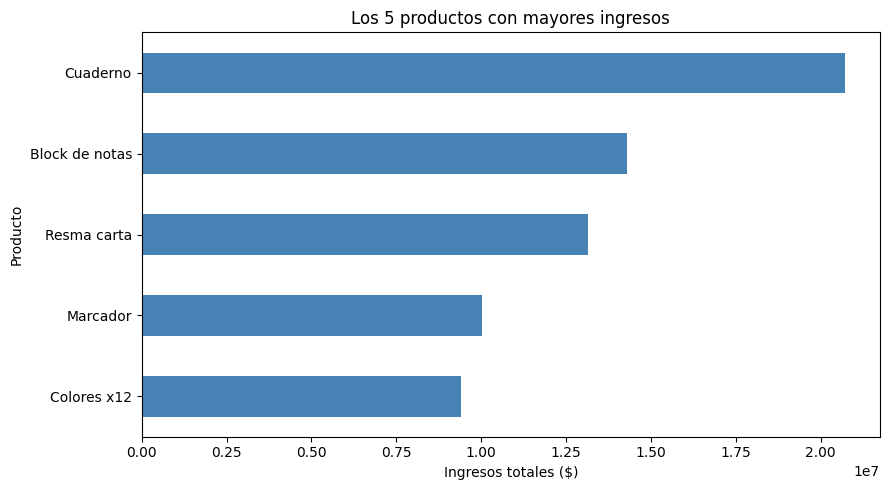

In [34]:
# Ejercicio 1
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)

ax = top_productos.sort_values().plot.barh(
    figsize=(9, 5),
    color="steelblue"
)

ax.set_title("Los 5 productos con mayores ingresos")
ax.set_xlabel("Ingresos totales ($)")
ax.set_ylabel("Producto")

plt.tight_layout()
plt.show()


In [35]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

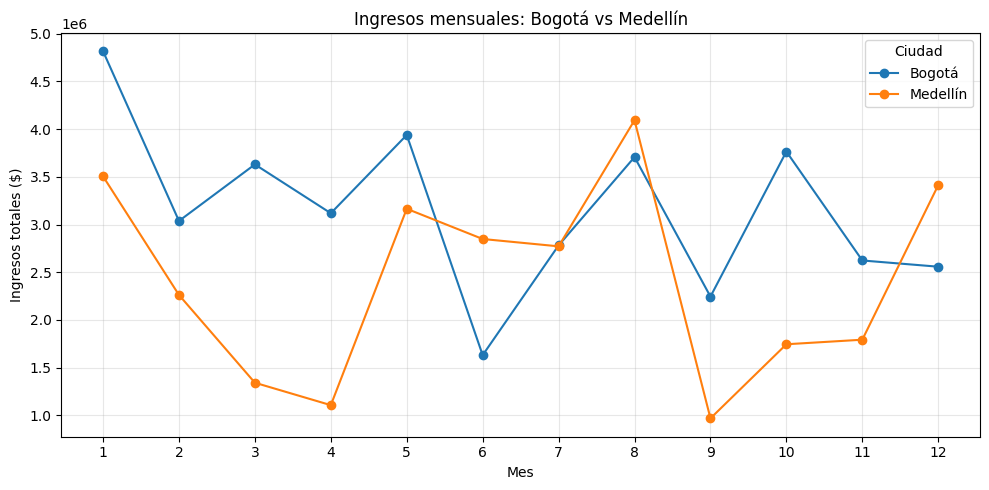

ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


In [36]:
# Ejercicio 2
ventas_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

ing_mes_ciudad = ventas_ciudades.pivot_table(
    index="mes",
    columns="ciudad",
    values="total",
    aggfunc="sum"
)

ing_mes_ciudad.plot.line(
    marker="o",
    figsize=(10, 5)
)

plt.title("Ingresos mensuales: Bogotá vs Medellín")
plt.xlabel("Mes")
plt.ylabel("Ingresos totales ($)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(title="Ciudad")
plt.tight_layout()
plt.show()

display(ing_mes_ciudad)

In [37]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

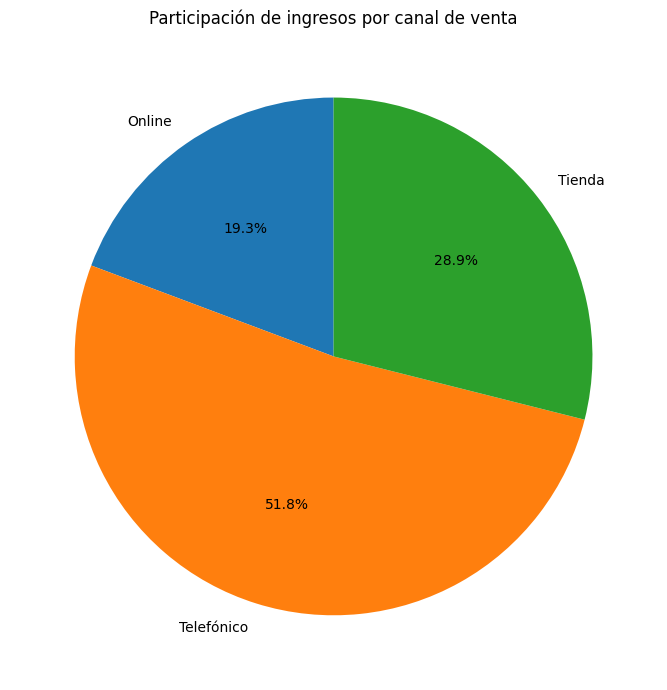

,total
canal,
Online,22887574
Telefónico,61450716
Tienda,34329722


In [38]:
# Ejercicio 3
ing_canal = df.groupby("canal")["total"].sum()

ing_canal.plot.pie(
    autopct="%1.1f%%",
    figsize=(7, 7),
    startangle=90
)

plt.title("Participación de ingresos por canal de venta")
plt.ylabel("")
plt.tight_layout()
plt.show()

display(ing_canal)

In [39]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

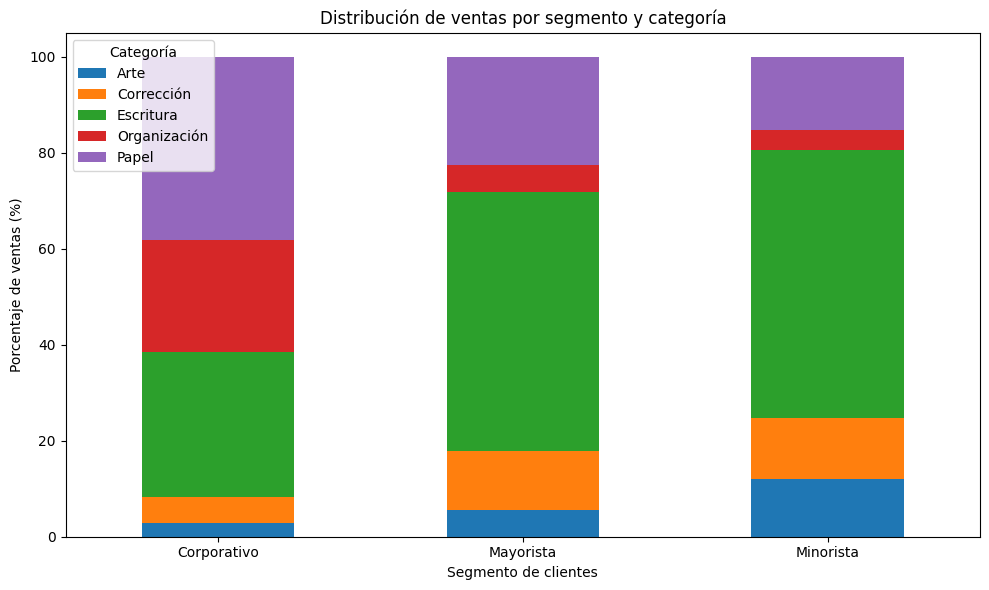

categoria,Arte,Corrección,Escritura,Organización,Papel
segmento,,,,,
Corporativo,2.807775,5.399568,30.237581,23.326134,38.228942
Mayorista,5.623472,12.224939,54.034230,5.623472,22.493888
Minorista,12.056738,12.765957,55.762411,4.255319,15.159574


In [40]:
# Ejercicio 4
tabla_seg_cat = pd.crosstab(
    df["segmento"],
    df["categoria"],
    normalize="index"
) * 100

tabla_seg_cat.plot.bar(
    stacked=True,
    figsize=(10, 6)
)

plt.title("Distribución de ventas por segmento y categoría")
plt.xlabel("Segmento de clientes")
plt.ylabel("Porcentaje de ventas (%)")
plt.xticks(rotation=0)
plt.legend(title="Categoría")
plt.tight_layout()
plt.show()

display(tabla_seg_cat)

In [41]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

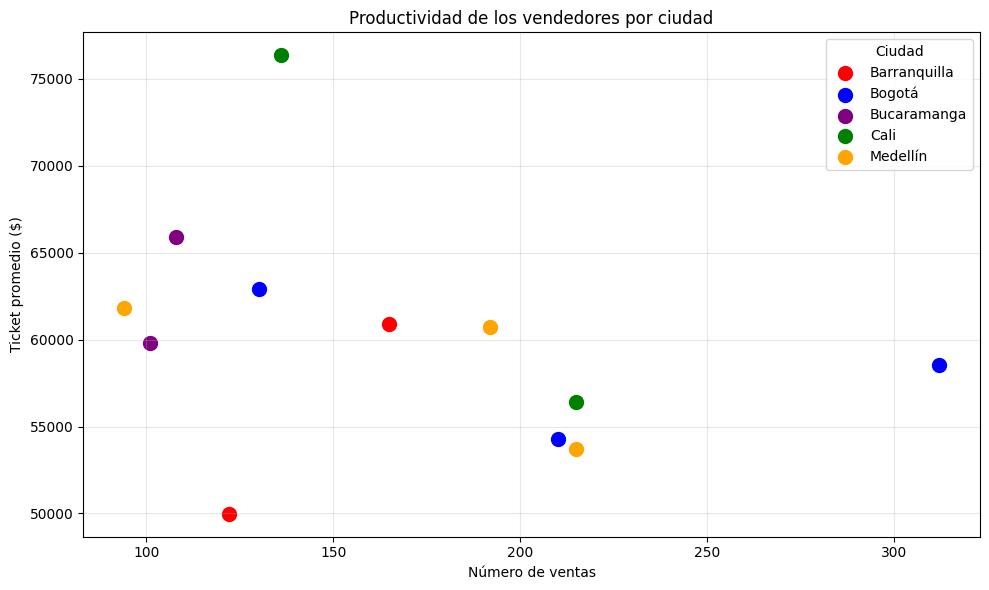

,vendedor,ciudad,n_ventas,ticket_prom
0,Andrés Rojas,Medellín,192,60729.104167
1,Camilo Pardo,Bogotá,210,54276.595238
2,Daniela Ríos,Bogotá,130,62903.423077
3,Esteban Uribe,Medellín,94,61833.978723
4,Isabela Mora,Bucaramanga,108,65873.037037
5,Julián Cortés,Cali,215,56389.920930
6,Laura Gómez,Bogotá,312,58564.371795
7,Mateo Peña,Barranquilla,165,60888.484848
8,Paula Vargas,Cali,136,76343.213235
9,Santiago Duarte,Bucaramanga,101,59798.841584


In [42]:
# Ejercicio 5
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

colores = {
    "Bogotá": "blue",
    "Medellín": "orange",
    "Cali": "green",
    "Barranquilla": "red",
    "Bucaramanga": "purple"
}

plt.figure(figsize=(10, 6))

for ciudad, datos in vend.groupby("ciudad"):
    plt.scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        color=colores[ciudad],
        label=ciudad,
        s=100
    )

plt.title("Productividad de los vendedores por ciudad")
plt.xlabel("Número de ventas")
plt.ylabel("Ticket promedio ($)")
plt.legend(title="Ciudad")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(vend)

In [43]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

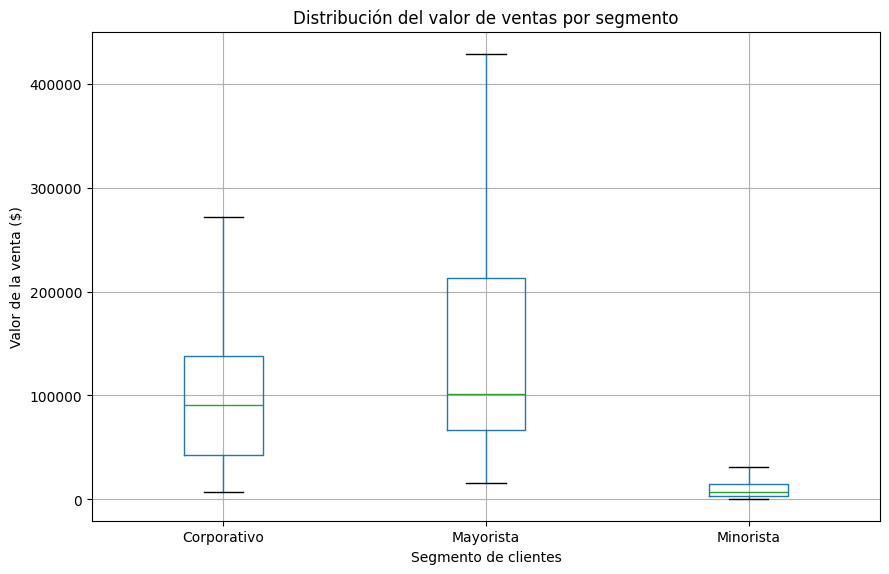

,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
950,V0951,2025-07-01,Medellín,Online,Corporativo,Sofía Mejía,Resma carta,Papel,Transferencia,4,19100,0.00,76400,7
951,V0952,2025-07-01,Cali,Online,Minorista,Paula Vargas,Esfero,Escritura,Efectivo,1,1250,0.00,1250,7
952,V0953,2025-07-01,Bogotá,Tienda,Mayorista,Laura Gómez,Cuaderno,Papel,Transferencia,40,3700,0.10,133200,7
953,V0954,2025-07-01,Cali,Tienda,Minorista,Paula Vargas,Resaltador,Escritura,Tarjeta,6,2950,0.00,17700,7
954,V0955,2025-07-01,Bogotá,Online,Minorista,Camilo Pardo,Marcador,Escritura,Tarjeta,7,2350,0.00,16450,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,V1996,2025-12-31,Bogotá,Tienda,Minorista,Laura Gómez,Témpera,Arte,Tarjeta,4,6350,0.00,25400,12
1996,V1997,2025-12-31,Cali,Tienda,Minorista,Julián Cortés,Lápiz,Escritura,Tarjeta,7,850,0.00,5950,12
1997,V1998,2025-12-31,Medellín,Online,Minorista,Andrés Rojas,Lápiz,Escritura,Tarjeta,4,850,0.00,3400,12
1998,V1999,2025-12-31,Barranquilla,Online,Minorista,Mateo Peña,Marcador,Escritura,Efectivo,6,2350,0.00,14100,12


In [44]:
# Ejercicio 6
sem2 = df[df["mes"] >= 7]

sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
    figsize=(9, 6)
)

plt.suptitle("")
plt.title("Distribución del valor de ventas por segmento")
plt.xlabel("Segmento de clientes")
plt.ylabel("Valor de la venta ($)")
plt.tight_layout()
plt.show()

display(sem2)

In [45]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [46]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Grafico 1: Top 5 productos
top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    title="Top 5 productos con mayores ingresos",
    color="steelblue"
)
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].set_ylabel("Producto")

# Grafico 2: Ingresos por ciudad y mes
ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    title="Ingresos mensuales: Bogota vs Medellin"
)
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].grid(True, alpha=0.3)

# Grafico 3: Ingresos por canal
ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    startangle=90,
    title="Participacion de ingresos por canal"
)
axs[0, 2].set_ylabel("")

# Grafico 4: Categorias por segmento
tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    title="Categorias por segmento (%)"
)
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].tick_params(axis="x", rotation=0)

# Grafico 5: Productividad vendedores
for ciudad, datos in vend.groupby("ciudad"):
    axs[1, 1].scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad,
        s=70
    )

axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Numero de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(title="Ciudad", fontsize=8)

# Grafico 6: Distribucion de ventas
sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
    ax=axs[1, 2]
)
axs[1, 2].set_title("Ventas por segmento (jul-dic)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta ($)")

# Titulo general del dashboard
fig.suptitle(
    "Ventas de la cadena de papelerias - 2025",
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Overwriting figura_base.py


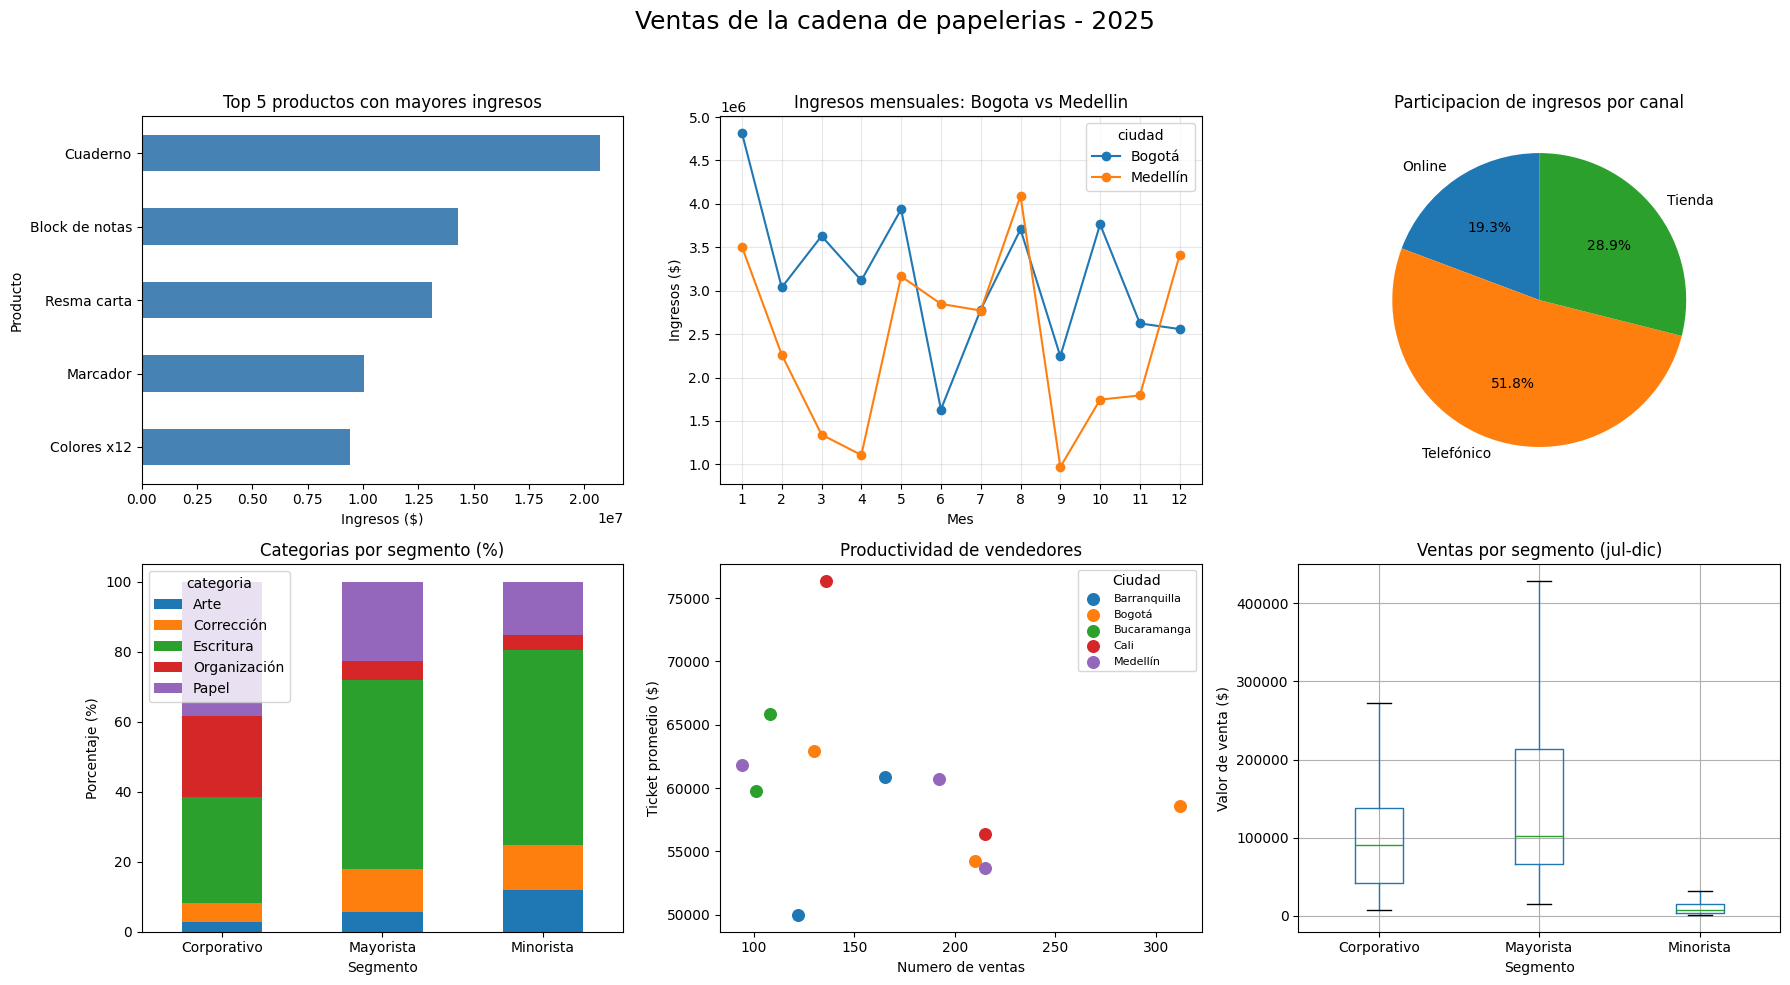

<Figure size 640x480 with 0 Axes>

In [47]:
%run -i figura_base.py

In [48]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [49]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Grafico 1: Top 5 productos
top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    title="Top 5 productos con mayores ingresos",
    color="steelblue"
)
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].set_ylabel("Producto")

# Grafico 2: Ingresos por ciudad y mes
ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    title="Ingresos mensuales: Bogota vs Medellin"
)
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].grid(True, alpha=0.3)

# Grafico 3: Ingresos por canal
ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    startangle=90,
    title="Participacion de ingresos por canal"
)
axs[0, 2].set_ylabel("")

# Grafico 4: Categorias por segmento
tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [50]:
prompt_v1 = """
PÚBLICO Y OBJETIVO:
Crear un dashboard profesional para la gerencia
de una cadena de papelerías con las ventas de 2025.
Conservar los seis gráficos en una figura de 2x3.

PALETA Y TIPOGRAFÍA:
Utilizar fondo gris claro, paneles blancos,
azul oscuro como color principal, naranja
para resaltar y verde para contrastar.
Asignar un color fijo a cada ciudad.
Usar títulos en negrita de 12 puntos y
un título general de 21 puntos.

TÍTULOS:
Los títulos deben comunicar conclusiones,
como que Cuaderno es el producto líder,
Bogotá lidera los ingresos y el canal
Telefónico genera más de la mitad.

EJES Y NÚMEROS:
Mostrar ingresos en millones de pesos COP,
porcentajes con un decimal y etiquetas
claras en español.

LIMPIEZA VISUAL:
Quitar bordes innecesarios, usar cuadrículas
suaves, mostrar valores en las barras
y utilizar leyendas sin marco.
Evitar que se superpongan los elementos.
Conservar los datos y tipos de gráficos.
"""

print(prompt_v1)   # cópialo en la IA, junto con tu código y las reglas


PÚBLICO Y OBJETIVO:
Crear un dashboard profesional para la gerencia
de una cadena de papelerías con las ventas de 2025.
Conservar los seis gráficos en una figura de 2x3.

PALETA Y TIPOGRAFÍA:
Utilizar fondo gris claro, paneles blancos,
azul oscuro como color principal, naranja
para resaltar y verde para contrastar.
Asignar un color fijo a cada ciudad.
Usar títulos en negrita de 12 puntos y
un título general de 21 puntos.

TÍTULOS:
Los títulos deben comunicar conclusiones,
como que Cuaderno es el producto líder,
Bogotá lidera los ingresos y el canal
Telefónico genera más de la mitad.

EJES Y NÚMEROS:
Mostrar ingresos en millones de pesos COP,
porcentajes con un decimal y etiquetas
claras en español.

LIMPIEZA VISUAL:
Quitar bordes innecesarios, usar cuadrículas
suaves, mostrar valores en las barras
y utilizar leyendas sin marco.
Evitar que se superpongan los elementos.
Conservar los datos y tipos de gráficos.



In [51]:
%%writefile figura_v1.py
# Pega aquí SOLO el código que te devolvió la IA (sin las líneas ```)
# Version 1: Dashboard profesional
from matplotlib.ticker import FuncFormatter

AZUL = "#183153"
NARANJA = "#EA8B47"
VERDE = "#32A99A"
FONDO = "#F2F5FA"

COLORES_CIUDAD = {
    "Bogotá": AZUL,
    "Medellín": NARANJA,
    "Cali": VERDE,
    "Barranquilla": "#A782C7",
    "Bucaramanga": "#D65F76"
}

fig, axs = plt.subplots(
    2, 3, figsize=(18, 10), facecolor=FONDO
)

for ax in axs.flat:
    ax.set_facecolor("white")
    for borde in ax.spines.values():
        borde.set_visible(False)
    ax.tick_params(colors="#475569", labelsize=9)
    ax.title.set_color(AZUL)
    ax.title.set_fontweight("bold")

# GRAFICO 1: Productos con mayores ingresos

top_productos.sort_values().div(1000000).plot.barh(
    ax=axs[0, 0],
    color=AZUL,
    legend=False
)

axs[0, 0].set_title(
    "Cuaderno es el producto líder", loc="left"
)
axs[0, 0].set_xlabel("Ingresos (millones COP)")
axs[0, 0].set_ylabel("")
axs[0, 0].grid(axis="x", alpha=0.15)

for barra in axs[0, 0].patches:
    valor = barra.get_width()
    axs[0, 0].text(
        valor + 0.3,
        barra.get_y() + barra.get_height()/2,
        f"${valor:.1f} M",
        va="center",
        fontsize=9
    )

axs[0, 0].set_xlim(
    0, top_productos.max()/1000000 * 1.3
)

# GRAFICO 2: Ingresos mensuales por ciudad

for ciudad in ["Bogotá", "Medellín"]:
    axs[0, 1].plot(
        ing_mes_ciudad.index,
        ing_mes_ciudad[ciudad] / 1000000,
        marker="o",
        linewidth=2,
        color=COLORES_CIUDAD[ciudad],
        label=ciudad
    )

axs[0, 1].set_title(
    "Bogotá lidera el acumulado anual", loc="left"
)
axs[0, 1].set_xlabel("Mes de 2025")
axs[0, 1].set_ylabel("Ingresos (millones COP)")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].grid(alpha=0.15)
axs[0, 1].legend(frameon=False)

# GRAFICO 3: Ingresos por canal

colores_canales = {
    "Telefónico": AZUL,
    "Tienda": NARANJA,
    "Online": VERDE
}

ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    startangle=90,
    colors=[colores_canales[c] for c in ing_canal.index]
)

axs[0, 2].set_title(
    "Telefónico aporta más de la mitad", loc="left"
)
axs[0, 2].set_ylabel("")

# GRAFICO 4: Categorías por segmento

colores_cat = [
    "#A2B7D7",
    "#F6BA83",
    AZUL,
    VERDE,
    "#A78BCE"
]

tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    color=colores_cat
)

axs[1, 0].set_title(
    "Escritura domina en 2 segmentos", loc="left"
)
axs[1, 0].set_xlabel("")
axs[1, 0].set_ylabel("Participación de ventas (%)")
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].legend(
    title="Categoría",
    fontsize=8,
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1, 1)
)

# GRAFICO 5: Productividad de vendedores

for ciudad, datos in vend.groupby("ciudad"):
    axs[1, 1].scatter(
        datos["n_ventas"],
        datos["ticket_prom"] / 1000,
        color=COLORES_CIUDAD[ciudad],
        label=ciudad,
        s=75
    )

axs[1, 1].set_title(
    "Más ventas no implica mayor ticket", loc="left"
)
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio (miles COP)")
axs[1, 1].grid(alpha=0.15)
axs[1, 1].legend(fontsize=7, frameon=False, ncol=2)

# GRAFICO 6: Ventas por segmento

sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
    ax=axs[1, 2],
    boxprops={"color": AZUL},
    medianprops={"color": NARANJA, "linewidth": 2}
)

axs[1, 2].set_title(
    "Mayoristas: mediana de venta más alta",
    loc="left"
)
axs[1, 2].set_xlabel("")
axs[1, 2].set_ylabel("Valor de venta (miles COP)")
axs[1, 2].yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x/1000:,.0f}")
)
axs[1, 2].grid(axis="y", alpha=0.15)

# TITULO GENERAL DEL DASHBOARD

fig.suptitle(
    "PAPELERÍAS 2025 | TABLERO DE VENTAS",
    fontsize=21,
    fontweight="bold",
    color=AZUL
)

fig.tight_layout(
    rect=[0.02, 0.04, 0.98, 0.94],
    w_pad=2,
    h_pad=2.5
)

fig.text(
    0.02, 0.015,
    "Fuente: ventas_papelerias_2025.csv",
    fontsize=9,
    color="#64748B"
)

Overwriting figura_v1.py


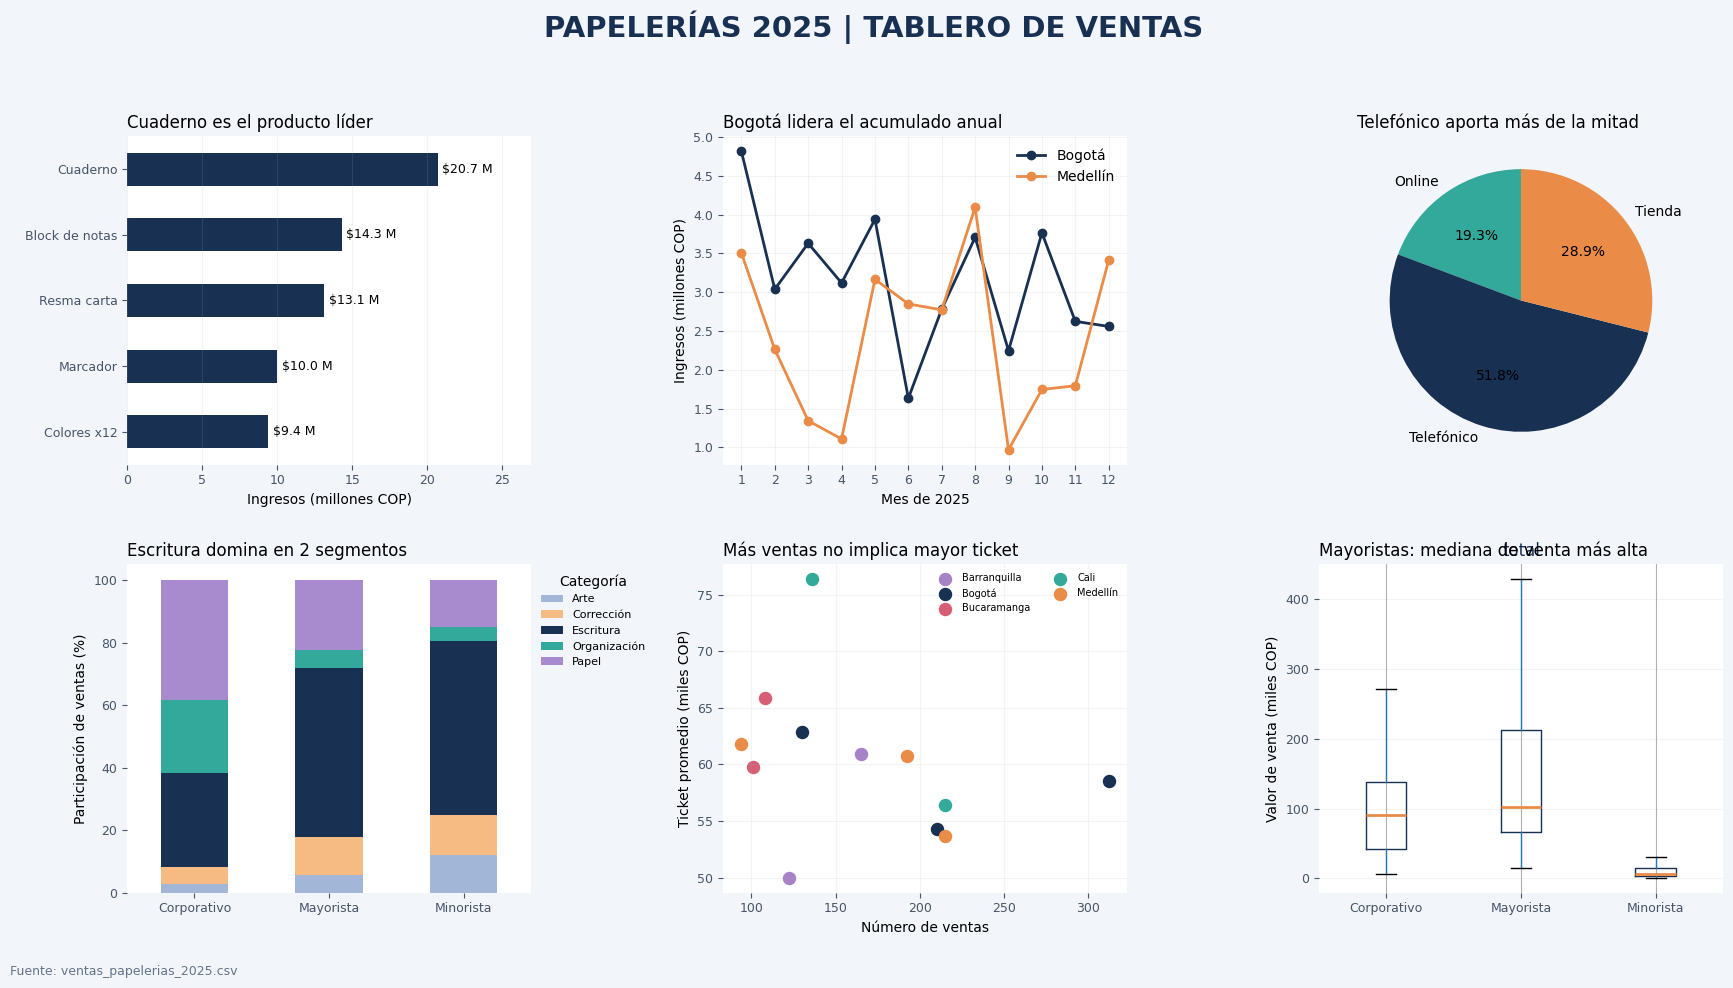

In [52]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [53]:

prompt_v2 = prompt_v1 + """

AJUSTES PARA LA VERSION 2:

Después de revisar la primera versión, quiero
un diseño claramente diferente y más llamativo.

1. CAMBIO COMPLETO DE PALETA:
Sustituye el fondo claro por un fondo azul marino
oscuro (#0B1424) y paneles azul oscuro (#16243A).
Utiliza amarillo (#FFD166), turquesa (#28D9C3),
coral (#FF7A90) y morado (#9B8BFF) como acentos.
Los títulos y etiquetas deben tener alto contraste.

2. INDICADORES PRINCIPALES:
Agrega en la parte superior tres tarjetas con:
número total de ventas, ingresos totales en
millones COP y porcentaje del canal Telefónico.

3. PRODUCTOS:
Destaca la barra del producto Cuaderno en
amarillo y deja las demás en gris azulado.

4. CANALES:
Transforma el gráfico circular en una dona,
mostrando el 51.8% del canal Telefónico
en el centro.

5. EVOLUCIÓN MENSUAL:
Utiliza líneas turquesa y coral.
Destaca los meses de mayores ingresos.

6. PRESENTACIÓN:
Usa títulos blancos en negrita, gráficos
más contrastados y leyendas legibles.
Mantén seis gráficos en una figura 2x3.
No modifiques los datos ni los cálculos.
Estos ajustes reemplazan las instrucciones
de colores de la versión 1.
"""

print(prompt_v2)



PÚBLICO Y OBJETIVO:
Crear un dashboard profesional para la gerencia
de una cadena de papelerías con las ventas de 2025.
Conservar los seis gráficos en una figura de 2x3.

PALETA Y TIPOGRAFÍA:
Utilizar fondo gris claro, paneles blancos,
azul oscuro como color principal, naranja
para resaltar y verde para contrastar.
Asignar un color fijo a cada ciudad.
Usar títulos en negrita de 12 puntos y
un título general de 21 puntos.

TÍTULOS:
Los títulos deben comunicar conclusiones,
como que Cuaderno es el producto líder,
Bogotá lidera los ingresos y el canal
Telefónico genera más de la mitad.

EJES Y NÚMEROS:
Mostrar ingresos en millones de pesos COP,
porcentajes con un decimal y etiquetas
claras en español.

LIMPIEZA VISUAL:
Quitar bordes innecesarios, usar cuadrículas
suaves, mostrar valores en las barras
y utilizar leyendas sin marco.
Evitar que se superpongan los elementos.
Conservar los datos y tipos de gráficos.


AJUSTES PARA LA VERSION 2:

Después de revisar la primera versión, quiero
u

In [54]:
%%writefile figura_v2.py
# Pega aquí el código que te devolvió la IA para la versión 2
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter

# Nueva paleta oscura
FONDO = "#0B1424"
PANEL = "#16243A"
TEXTO = "#F5F8FF"
SUAVE = "#ACBCD2"
AMARILLO = "#FFD166"
TURQUESA = "#28D9C3"
CORAL = "#FF7A90"
MORADO = "#9B8BFF"

COLORES_CIUDAD = {
    "Bogotá": TURQUESA,
    "Medellín": CORAL,
    "Cali": MORADO,
    "Barranquilla": AMARILLO,
    "Bucaramanga": "#6CB8FF"
}

fig, axs = plt.subplots(
    2, 3, figsize=(20, 11.5), facecolor=FONDO
)

for ax in axs.flat:
    ax.set_facecolor(PANEL)
    for borde in ax.spines.values():
        borde.set_color("#304058")
    ax.tick_params(colors=SUAVE, labelsize=9, length=0)
    ax.xaxis.label.set_color(SUAVE)
    ax.yaxis.label.set_color(SUAVE)
    ax.set_axisbelow(True)

def encabezado(ax, texto):
    ax.set_title(
        texto, loc="left", fontweight="bold",
        fontsize=11.8, color=TEXTO, pad=14
    )

def rejilla(ax, eje="y"):
    ax.grid(
        axis=eje, color="#45566C",
        alpha=0.35, linewidth=0.8
    )

# GRAFICO 1 - TOP 5 PRODUCTOS

ax = axs[0, 0]
prod = top_productos.sort_values() / 1000000

colores = [
    AMARILLO if p == "Cuaderno" else "#60748D"
    for p in prod.index
]

prod.plot.barh(
    ax=ax, color=colores, width=0.58,
    legend=False
)

encabezado(ax, "01   CUADERNO ENCABEZA EL RANKING")
ax.set_xlabel("Ingresos - millones COP")
ax.set_ylabel("")
ax.set_xlim(0, prod.max() * 1.32)
rejilla(ax, "x")

for barra in ax.patches:
    valor = barra.get_width()
    ax.text(
        valor + 0.28,
        barra.get_y() + barra.get_height()/2,
        f"{valor:.1f} M",
        va="center", color=TEXTO,
        fontsize=9, fontweight="bold"
    )

# GRAFICO 2 - EVOLUCION MENSUAL

ax = axs[0, 1]

for ciudad in ["Bogotá", "Medellín"]:
    valores = ing_mes_ciudad[ciudad] / 1000000

    ax.plot(
        valores.index, valores,
        color=COLORES_CIUDAD[ciudad],
        marker="o", linewidth=2.8,
        markersize=5, label=ciudad
    )

    mes = valores.idxmax()

    ax.annotate(
        f"{valores.loc[mes]:.1f} M",
        xy=(mes, valores.loc[mes]),
        xytext=(
            0, -21 if ciudad == "Medellín" else 12
        ),
        textcoords="offset points",
        ha="center", fontsize=9,
        color=COLORES_CIUDAD[ciudad],
        fontweight="bold"
    )

encabezado(ax, "02   BOGOTÁ LIDERA EL AÑO")
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Ingresos - millones COP")
ax.set_xticks(range(1, 13))
ax.set_ylim(0.4, 5.55)
rejilla(ax)

ax.legend(
    frameon=False, labelcolor=TEXTO,
    fontsize=9, ncol=2, loc="upper right"
)

# GRAFICO 3 - DONA POR CANAL

ax = axs[0, 2]

canales = ing_canal.reindex([
    "Telefónico", "Tienda", "Online"
])

ax.pie(
    canales,
    colors=[AMARILLO, MORADO, TURQUESA],
    startangle=90,
    counterclock=False,
    wedgeprops={
        "width": 0.28,
        "edgecolor": PANEL,
        "linewidth": 3
    }
)

pct = (
    canales["Telefónico"] / canales.sum()
) * 100

ax.text(
    0, 0.10, f"{pct:.1f}%",
    ha="center", va="center",
    fontsize=27, fontweight="bold",
    color=AMARILLO
)

ax.text(
    0, -0.20, "TELEFÓNICO",
    ha="center", va="center",
    fontsize=10, color=SUAVE
)

encabezado(ax, "03   TELEFÓNICO SUPERA EL 50 %")

etiquetas = [
    f"{c}: {v/canales.sum()*100:.1f}%"
    for c, v in canales.items()
]

ax.legend(
    etiquetas,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=3, frameon=False,
    fontsize=8, labelcolor=TEXTO
)

# GRAFICO 4 - CATEGORIAS POR SEGMENTO

ax = axs[1, 0]

colores_cat = [
    "#577FA7", CORAL, TURQUESA,
    MORADO, AMARILLO
]

tabla_seg_cat.plot.bar(
    ax=ax, stacked=True,
    color=colores_cat, width=0.63
)

encabezado(
    ax, "04   ESCRITURA DOMINA EN 2 SEGMENTOS"
)

ax.set_xlabel("")
ax.set_ylabel("Participación de ventas (%)")
ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, 105)
rejilla(ax)

ax.legend(
    frameon=False, fontsize=8,
    ncol=3, labelcolor=TEXTO,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10)
)

# GRAFICO 5 - PRODUCTIVIDAD

ax = axs[1, 1]

for ciudad, datos in vend.groupby("ciudad"):
    ax.scatter(
        datos["n_ventas"],
        datos["ticket_prom"] / 1000,
        s=100,
        color=COLORES_CIUDAD[ciudad],
        label=ciudad,
        alpha=0.95,
        edgecolors=PANEL
    )

encabezado(ax, "05   MÁS VENTAS ≠ MAYOR TICKET")
ax.set_xlabel("Número de ventas")
ax.set_ylabel("Ticket promedio - miles COP")
rejilla(ax, "both")

ax.legend(
    frameon=False, fontsize=8,
    labelcolor=TEXTO, ncol=2,
    loc="upper right"
)

# GRAFICO 6 - BOXPLOT

ax = axs[1, 2]

sem2.boxplot(
    column="total",
    by="segmento",
    ax=ax,
    showfliers=False,
    grid=False,
    patch_artist=True,
    boxprops={
        "facecolor": "#264A60",
        "edgecolor": TURQUESA,
        "linewidth": 1.8
    },
    medianprops={
        "color": AMARILLO,
        "linewidth": 2.8
    },
    whiskerprops={
        "color": TURQUESA
    },
    capprops={
        "color": TURQUESA
    }
)

encabezado(
    ax, "06   MAYORISTAS: MEDIANA MÁS ALTA"
)

ax.set_xlabel("")
ax.set_ylabel("Valor de venta - miles COP")

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x/1000:,.0f}"
    )
)

rejilla(ax)

# ENCABEZADO GENERAL

fig.suptitle("")

fig.text(
    0.065, 0.958,
    "PAPELERÍAS  /  2025",
    color=AMARILLO,
    fontsize=22,
    fontweight="bold"
)

fig.text(
    0.065, 0.914,
    "RADIOGRAFÍA COMERCIAL - Dashboard gerencial",
    color=TEXTO,
    fontsize=13
)

# TARJETAS DE INDICADORES

kpis = [
    (
        "VENTAS REGISTRADAS",
        f"{len(df):,}".replace(",", "."),
        TURQUESA
    ),
    (
        "INGRESOS TOTALES",
        f"$ {df['total'].sum()/1000000:.1f} M",
        AMARILLO
    ),
    (
        "PESO DEL CANAL TELEFÓNICO",
        f"{pct:.1f}%",
        CORAL
    )
]

for i, (etiqueta, valor, acento) in enumerate(kpis):
    x = 0.065 + i * 0.31

    tarjeta = FancyBboxPatch(
        (x, 0.799), 0.275, 0.082,
        boxstyle="round,pad=0.009,rounding_size=0.012",
        transform=fig.transFigure,
        facecolor=PANEL,
        edgecolor="#344860",
        linewidth=0.8
    )

    fig.add_artist(tarjeta)

    fig.text(
        x + 0.015, 0.854,
        etiqueta, color=SUAVE, fontsize=9
    )

    fig.text(
        x + 0.015, 0.815,
        valor, color=acento,
        fontsize=20, fontweight="bold"
    )

# AJUSTAR ESPACIOS

fig.subplots_adjust(
    left=0.065, right=0.965,
    top=0.755, bottom=0.105,
    wspace=0.32, hspace=0.47
)

fig.text(
    0.065, 0.023,
    "Fuente: ventas_papelerias_2025.csv - 2025",
    color=SUAVE, fontsize=9
)


Overwriting figura_v2.py


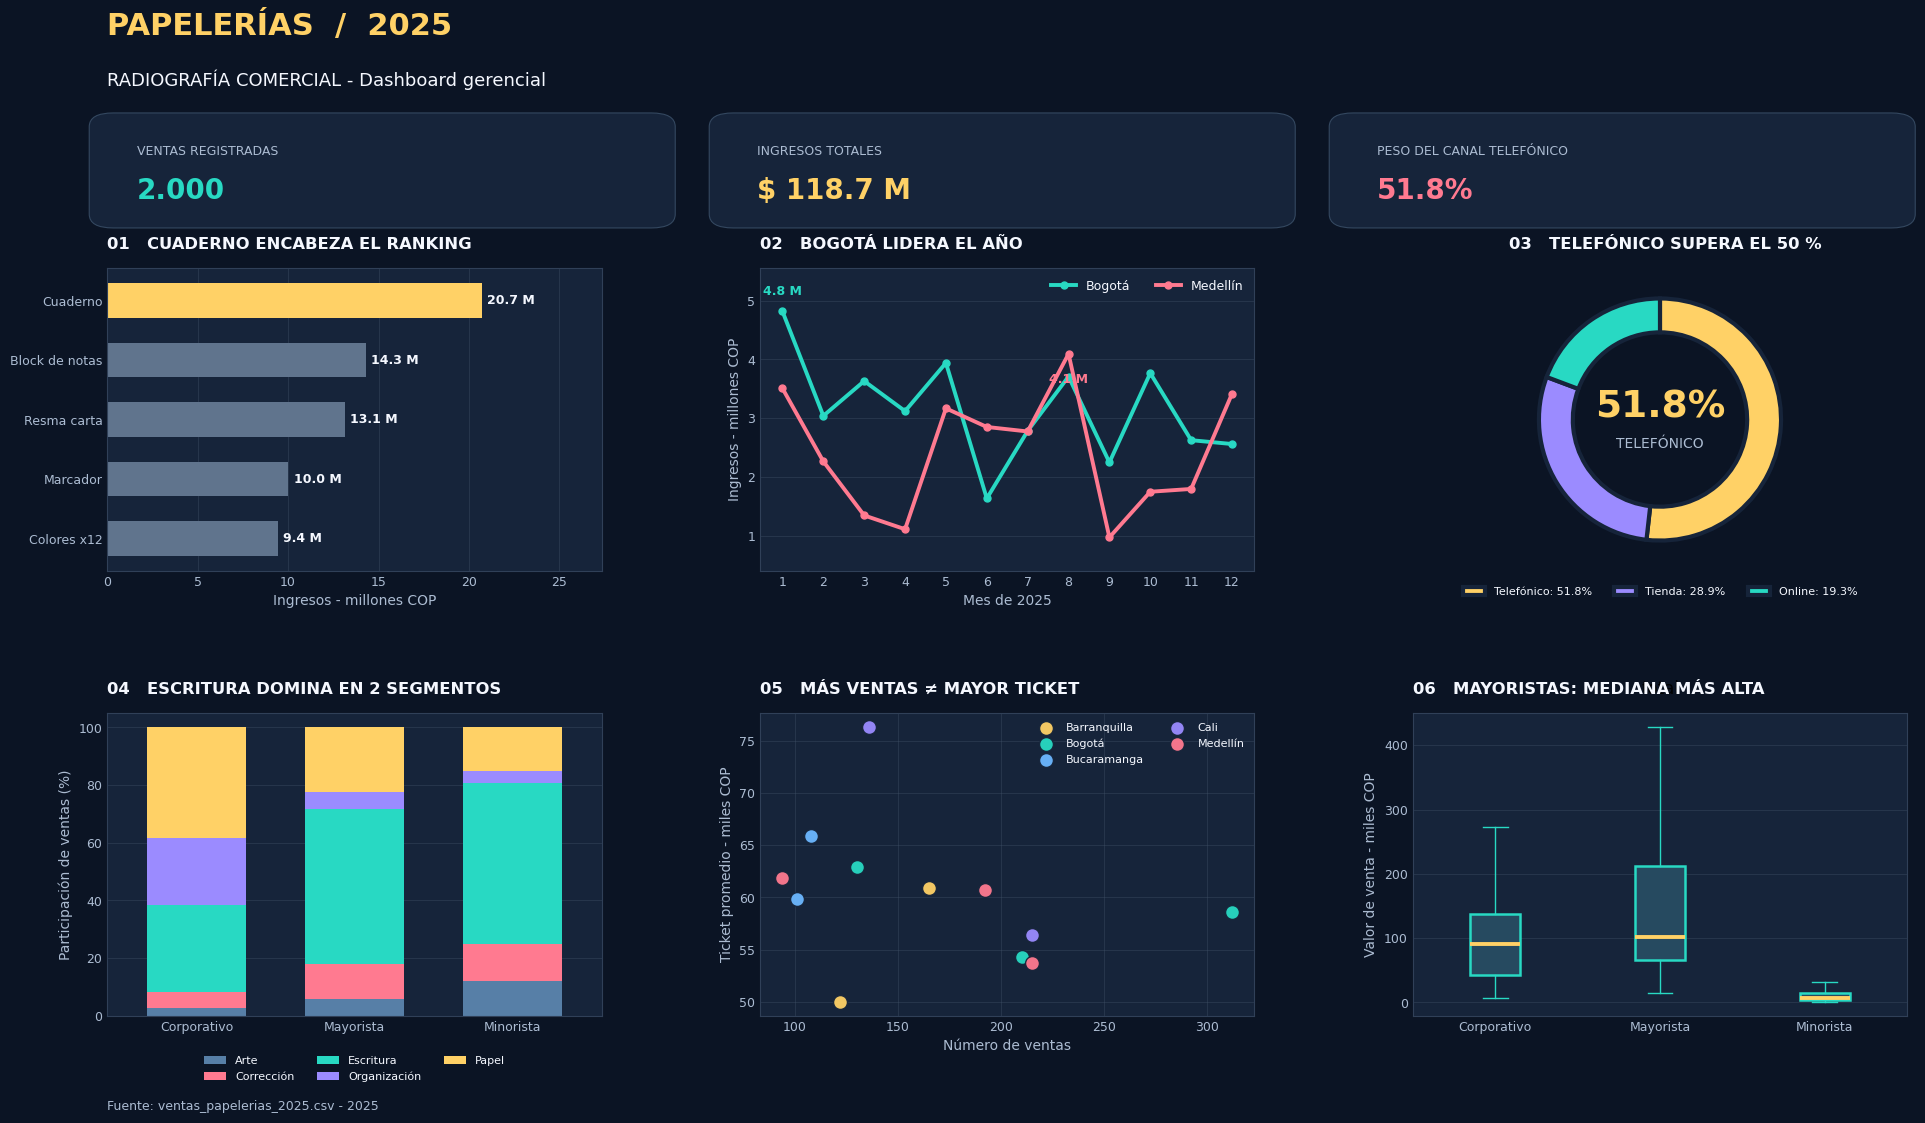

In [55]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [56]:

prompt_v3 = prompt_v2 + """

AJUSTES FINALES PARA LA VERSION 3:

Después de comparar las versiones anteriores,
quiero probar un diseño editorial más minimalista.

1. PALETA:
Sustituye el fondo azul oscuro de la versión 2
por un fondo crema claro (#F5F3EE).
Utiliza paneles blancos y títulos azul petróleo.
Usa coral (#E87563) y verde (#138A79)
como colores de énfasis.

2. DISTRIBUCION:
Conserva seis gráficos en una cuadrícula 2x3.
Elimina las tarjetas grandes de indicadores
para dar más espacio a los gráficos.
Coloca un encabezado limpio con título y
resumen de ventas en la parte superior.

3. LEGIBILIDAD:
Aumenta la separación entre gráficos.
Utiliza cuadrículas muy suaves.
Evita que las leyendas oculten datos y
usa etiquetas fáciles de interpretar.

4. PRODUCTOS Y CANALES:
Resalta Cuaderno en coral y deja las otras
barras en gris azulado.
Conserva el gráfico de dona y el porcentaje
del canal Telefónico en el centro.

5. GRAFICOS RESTANTES:
Conserva las líneas con sus máximos anotados,
las barras apiladas, el gráfico de dispersión
y el diagrama de cajas sin valores atípicos.
Mantén los colores de ciudad consistentes
dentro de la versión.

6. DATOS:
No cambies ningún cálculo, porcentaje,
variable ni resultado de la base original.
Usa únicamente pandas y matplotlib.
Guarda la figura final en la variable fig.
No incluyas plt.show() ni guardes imágenes.

Estas instrucciones reemplazan la paleta oscura
y las tarjetas de la versión anterior.
"""

print(prompt_v3)


PÚBLICO Y OBJETIVO:
Crear un dashboard profesional para la gerencia
de una cadena de papelerías con las ventas de 2025.
Conservar los seis gráficos en una figura de 2x3.

PALETA Y TIPOGRAFÍA:
Utilizar fondo gris claro, paneles blancos,
azul oscuro como color principal, naranja
para resaltar y verde para contrastar.
Asignar un color fijo a cada ciudad.
Usar títulos en negrita de 12 puntos y
un título general de 21 puntos.

TÍTULOS:
Los títulos deben comunicar conclusiones,
como que Cuaderno es el producto líder,
Bogotá lidera los ingresos y el canal
Telefónico genera más de la mitad.

EJES Y NÚMEROS:
Mostrar ingresos en millones de pesos COP,
porcentajes con un decimal y etiquetas
claras en español.

LIMPIEZA VISUAL:
Quitar bordes innecesarios, usar cuadrículas
suaves, mostrar valores en las barras
y utilizar leyendas sin marco.
Evitar que se superpongan los elementos.
Conservar los datos y tipos de gráficos.


AJUSTES PARA LA VERSION 2:

Después de revisar la primera versión, quiero
u

In [57]:
%%writefile figura_v3.py

import matplotlib.pyplot as plt

# PALETA DE COLORES
FONDO = "#F5F3EE"
BLANCO = "#FFFFFF"
TINTA = "#193044"
GRIS = "#627587"
VERDE = "#138A79"
CORAL = "#E87563"
MOSTAZA = "#D49A3B"
LILA = "#8678B9"
BORDE = "#E4E7E8"

colores_ciudad = {
    "Bogotá": TINTA,
    "Medellín": CORAL,
    "Cali": VERDE,
    "Barranquilla": MOSTAZA,
    "Bucaramanga": LILA
}

# CREAR DASHBOARD
fig, axs = plt.subplots(
    2, 3, figsize=(20, 12), facecolor=FONDO
)

for ax in axs.flat:
    ax.set_facecolor(BLANCO)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(colors=GRIS, labelsize=9, length=0)
    ax.xaxis.label.set_color(GRIS)
    ax.yaxis.label.set_color(GRIS)
    ax.set_axisbelow(True)

def encabezado(ax, titulo):
    ax.set_title(
        titulo, loc="left", fontsize=12,
        fontweight="bold", color=TINTA, pad=15
    )

def grilla(ax, eje="y"):
    ax.grid(
        axis=eje, color=BORDE,
        alpha=0.8, linewidth=0.8
    )

# GRAFICO 1: TOP 5 PRODUCTOS
ax = axs[0, 0]

ordenados = top_productos.sort_values() / 1000000

colores = [
    CORAL if p == "Cuaderno" else "#8FA5B1"
    for p in ordenados.index
]

ax.barh(
    ordenados.index,
    ordenados.values,
    color=colores,
    height=0.60
)

encabezado(
    ax, "01  Cuaderno concentra más ingresos"
)
ax.set_xlabel("Ingresos (millones COP)")
ax.set_xlim(0, ordenados.max() * 1.30)
grilla(ax, "x")

for y, valor in enumerate(ordenados.values):
    ax.text(
        valor + 0.2, y,
        f"${valor:.1f} M",
        va="center",
        color=TINTA,
        fontsize=9
    )

# GRAFICO 2: INGRESOS POR CIUDAD
ax = axs[0, 1]

for ciudad in ["Bogotá", "Medellín"]:
    serie = ing_mes_ciudad[ciudad] / 1000000

    ax.plot(
        serie.index,
        serie.values,
        color=colores_ciudad[ciudad],
        marker="o",
        linewidth=2.4,
        markersize=4.8,
        label=ciudad
    )

    mes_max = int(serie.idxmax())

    ax.annotate(
        f"{serie.loc[mes_max]:.1f} M",
        xy=(mes_max, serie.loc[mes_max]),
        xytext=(
            0, 11 if ciudad == "Bogotá" else -17
        ),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color=colores_ciudad[ciudad],
        fontweight="bold"
    )

encabezado(
    ax, "02  Bogotá lidera el acumulado anual"
)
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Ingresos (millones COP)")
ax.set_xticks(range(1, 13))
ax.set_ylim(
    0, ing_mes_ciudad.max().max() / 1000000 * 1.25
)
ax.legend(
    frameon=False, ncol=2,
    fontsize=9, loc="upper right"
)
grilla(ax)

# GRAFICO 3: DONA POR CANAL
ax = axs[0, 2]

canales = ing_canal.reindex([
    "Telefónico", "Tienda", "Online"
])

ax.pie(
    canales.values,
    startangle=90,
    counterclock=False,
    colors=[TINTA, MOSTAZA, VERDE],
    radius=0.88,
    wedgeprops={
        "width": 0.31,
        "edgecolor": BLANCO,
        "linewidth": 2
    }
)

pct_tel = (
    canales["Telefónico"] / canales.sum()
) * 100

ax.text(
    0, 0.08,
    f"{pct_tel:.1f}%",
    ha="center", va="center",
    color=TINTA,
    fontsize=24, fontweight="bold"
)

ax.text(
    0, -0.17,
    "Telefónico",
    ha="center", va="center",
    color=GRIS, fontsize=10
)

encabezado(
    ax, "03  Telefónico representa la mayoría"
)

etiquetas = [
    f"{nombre} {valor/canales.sum()*100:.1f}%"
    for nombre, valor in canales.items()
]

ax.legend(
    etiquetas,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3, frameon=False,
    fontsize=8
)
ax.set_ylabel("")

# GRAFICO 4: CATEGORIAS POR SEGMENTO
ax = axs[1, 0]

colores_cat = [
    "#A8B6C1", MOSTAZA, VERDE, LILA, CORAL
]

tabla_seg_cat.plot.bar(
    ax=ax,
    stacked=True,
    color=colores_cat,
    width=0.63,
    legend=False
)

encabezado(
    ax, "04  Las preferencias cambian por segmento"
)
ax.set_xlabel("")
ax.set_ylabel("Participación de operaciones (%)")
ax.set_ylim(0, 103)
ax.tick_params(axis="x", rotation=0)
grilla(ax)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=8
)

# GRAFICO 5: PRODUCTIVIDAD
ax = axs[1, 1]

for ciudad, datos in vend.groupby("ciudad"):
    ax.scatter(
        datos["n_ventas"],
        datos["ticket_prom"] / 1000,
        s=95,
        color=colores_ciudad[ciudad],
        label=ciudad,
        alpha=0.88,
        edgecolor=BLANCO,
        linewidth=0.9
    )

encabezado(
    ax, "05  Más ventas no equivale a mayor ticket"
)
ax.set_xlabel("Número de ventas")
ax.set_ylabel("Ticket promedio (miles COP)")
grilla(ax, "both")

ax.legend(
    ncol=2, fontsize=8,
    frameon=False, loc="upper right"
)

# GRAFICO 6: BOXPLOT
ax = axs[1, 2]

segmentos = [
    "Corporativo", "Mayorista", "Minorista"
]

valores = [
    sem2.loc[
        sem2["segmento"] == s, "total"
    ] / 1000
    for s in segmentos
]

bp = ax.boxplot(
    valores,
    showfliers=False,
    patch_artist=True,
    widths=0.48,
    medianprops={
        "color": CORAL,
        "linewidth": 2.7
    },
    boxprops={
        "edgecolor": TINTA,
        "linewidth": 1.2
    },
    whiskerprops={"color": GRIS},
    capprops={"color": GRIS}
)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(segmentos)

for caja, color in zip(
    bp["boxes"],
    ["#E8F1EE", "#F8EBD7", "#E8E9F4"]
):
    caja.set_facecolor(color)

encabezado(
    ax, "06  Mayoristas tienen la mediana más alta"
)
ax.set_ylabel("Valor de la venta (miles COP)")
ax.set_xlabel("")
grilla(ax)

# ENCABEZADO GENERAL
fig.suptitle("")

fig.text(
    0.055, 0.962,
    "ANÁLISIS COMERCIAL",
    color=VERDE,
    fontsize=11,
    fontweight="bold"
)

fig.text(
    0.055, 0.919,
    "Ventas de papelerías  |  2025",
    color=TINTA,
    fontsize=26,
    fontweight="bold"
)

fig.text(
    0.055, 0.886,
    "Una lectura ejecutiva de productos, regiones, canales y clientes",
    color=GRIS,
    fontsize=11
)

fig.text(
    0.95, 0.936,
    f"{len(df):,} operaciones",
    ha="right",
    color=TINTA,
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.95, 0.910,
    f"$ {df['total'].sum()/1000000:.1f} M COP en ingresos",
    ha="right",
    color=VERDE,
    fontsize=11
)

# AJUSTAR ESPACIOS
fig.subplots_adjust(
    left=0.055,
    right=0.97,
    top=0.825,
    bottom=0.13,
    wspace=0.38,
    hspace=0.55
)

fig.text(
    0.055, 0.025,
    "Fuente: ventas_papelerias_2025.csv - Segundo semestre solo en gráfico 06",
    fontsize=9,
    color=GRIS
)


Overwriting figura_v3.py


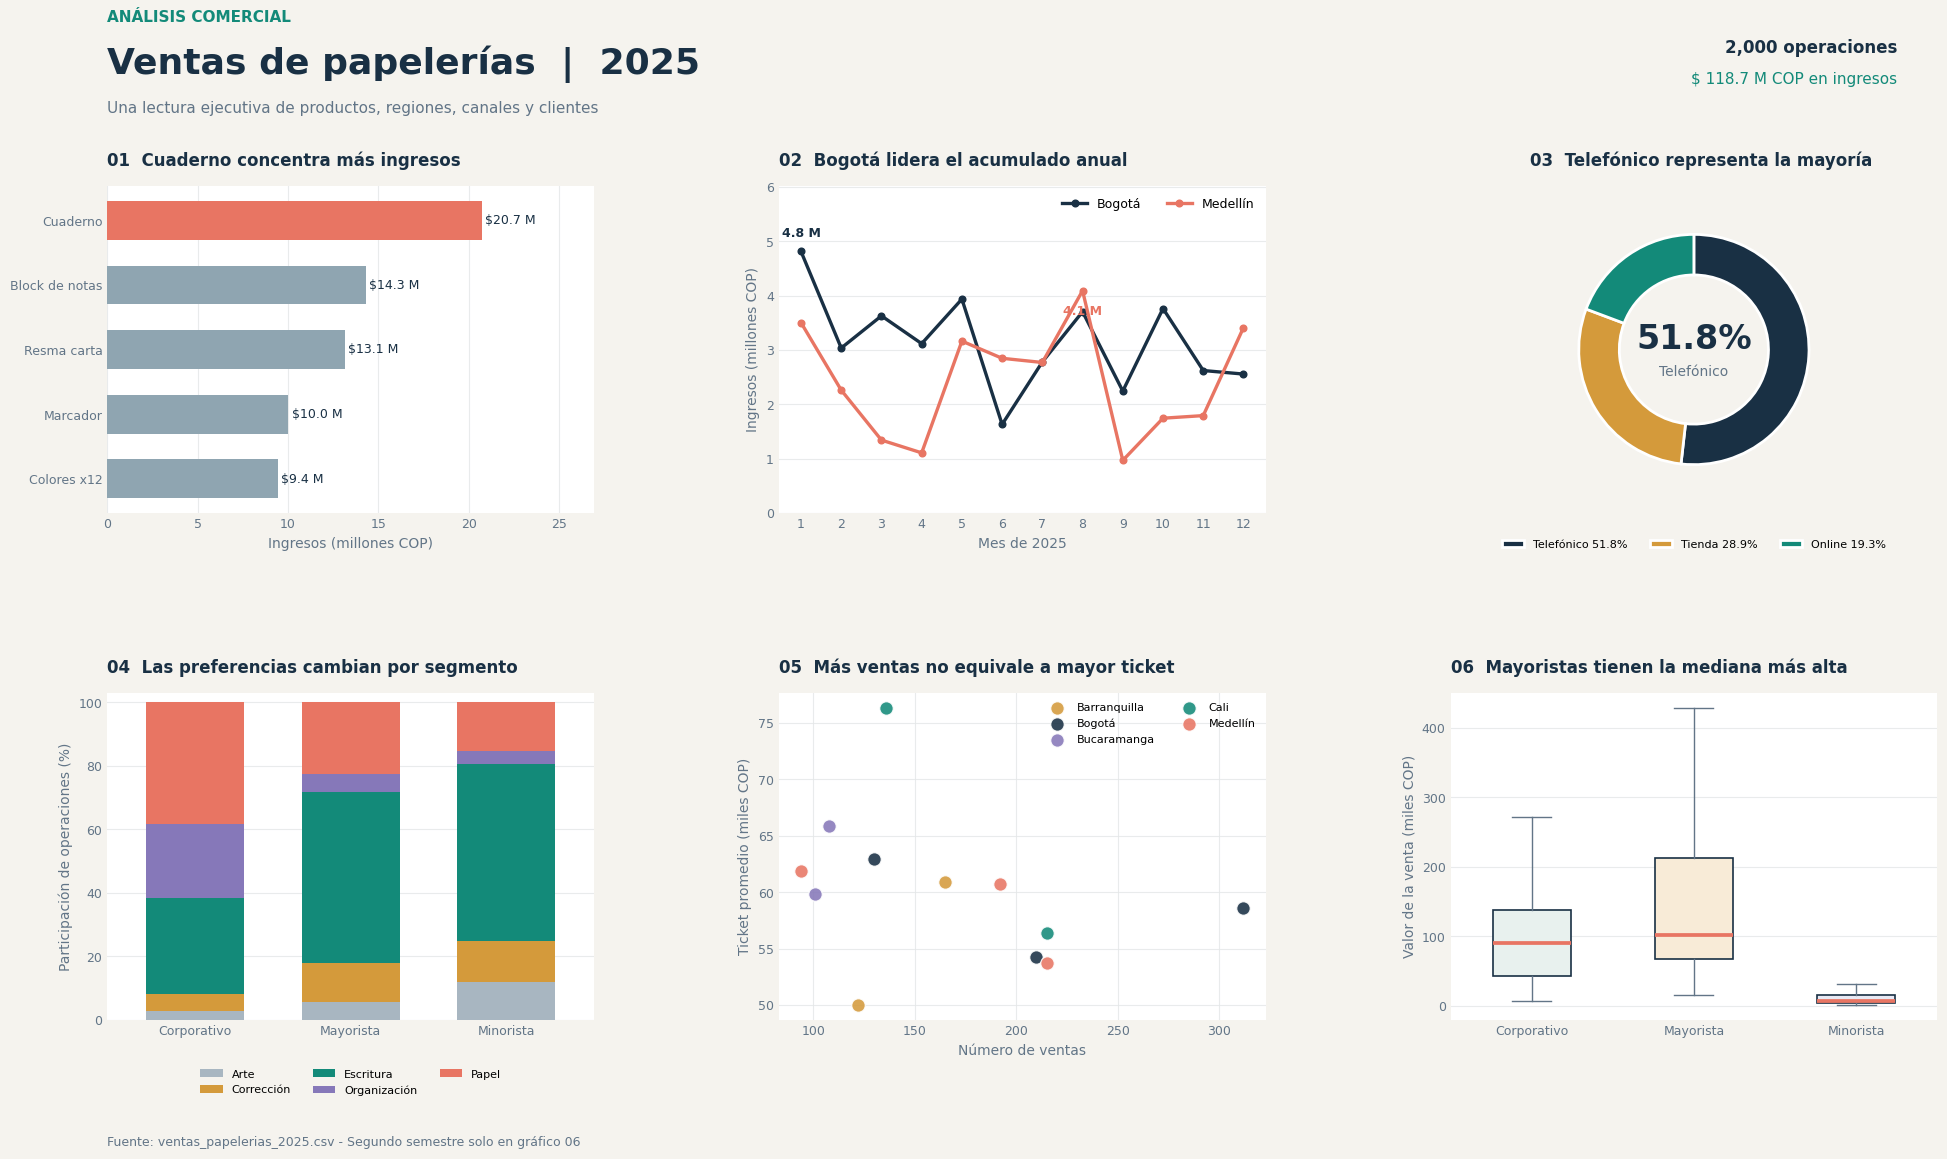

In [58]:
mostrar("v3")

In [59]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [60]:
figura_elegida = "v3"

hallazgos = [
    "Bogotá fue la ciudad con mayores ingresos en 2025, con $37.847.614, equivalentes al 31,9 % del total.",

    "El canal Telefónico generó $61.450.716, representando el 51,8 % de los ingresos totales de la cadena.",

    "Cuaderno fue el producto con mayores ingresos, alcanzando $20.712.345, equivalentes al 17,5 % del total."
]


In [61]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

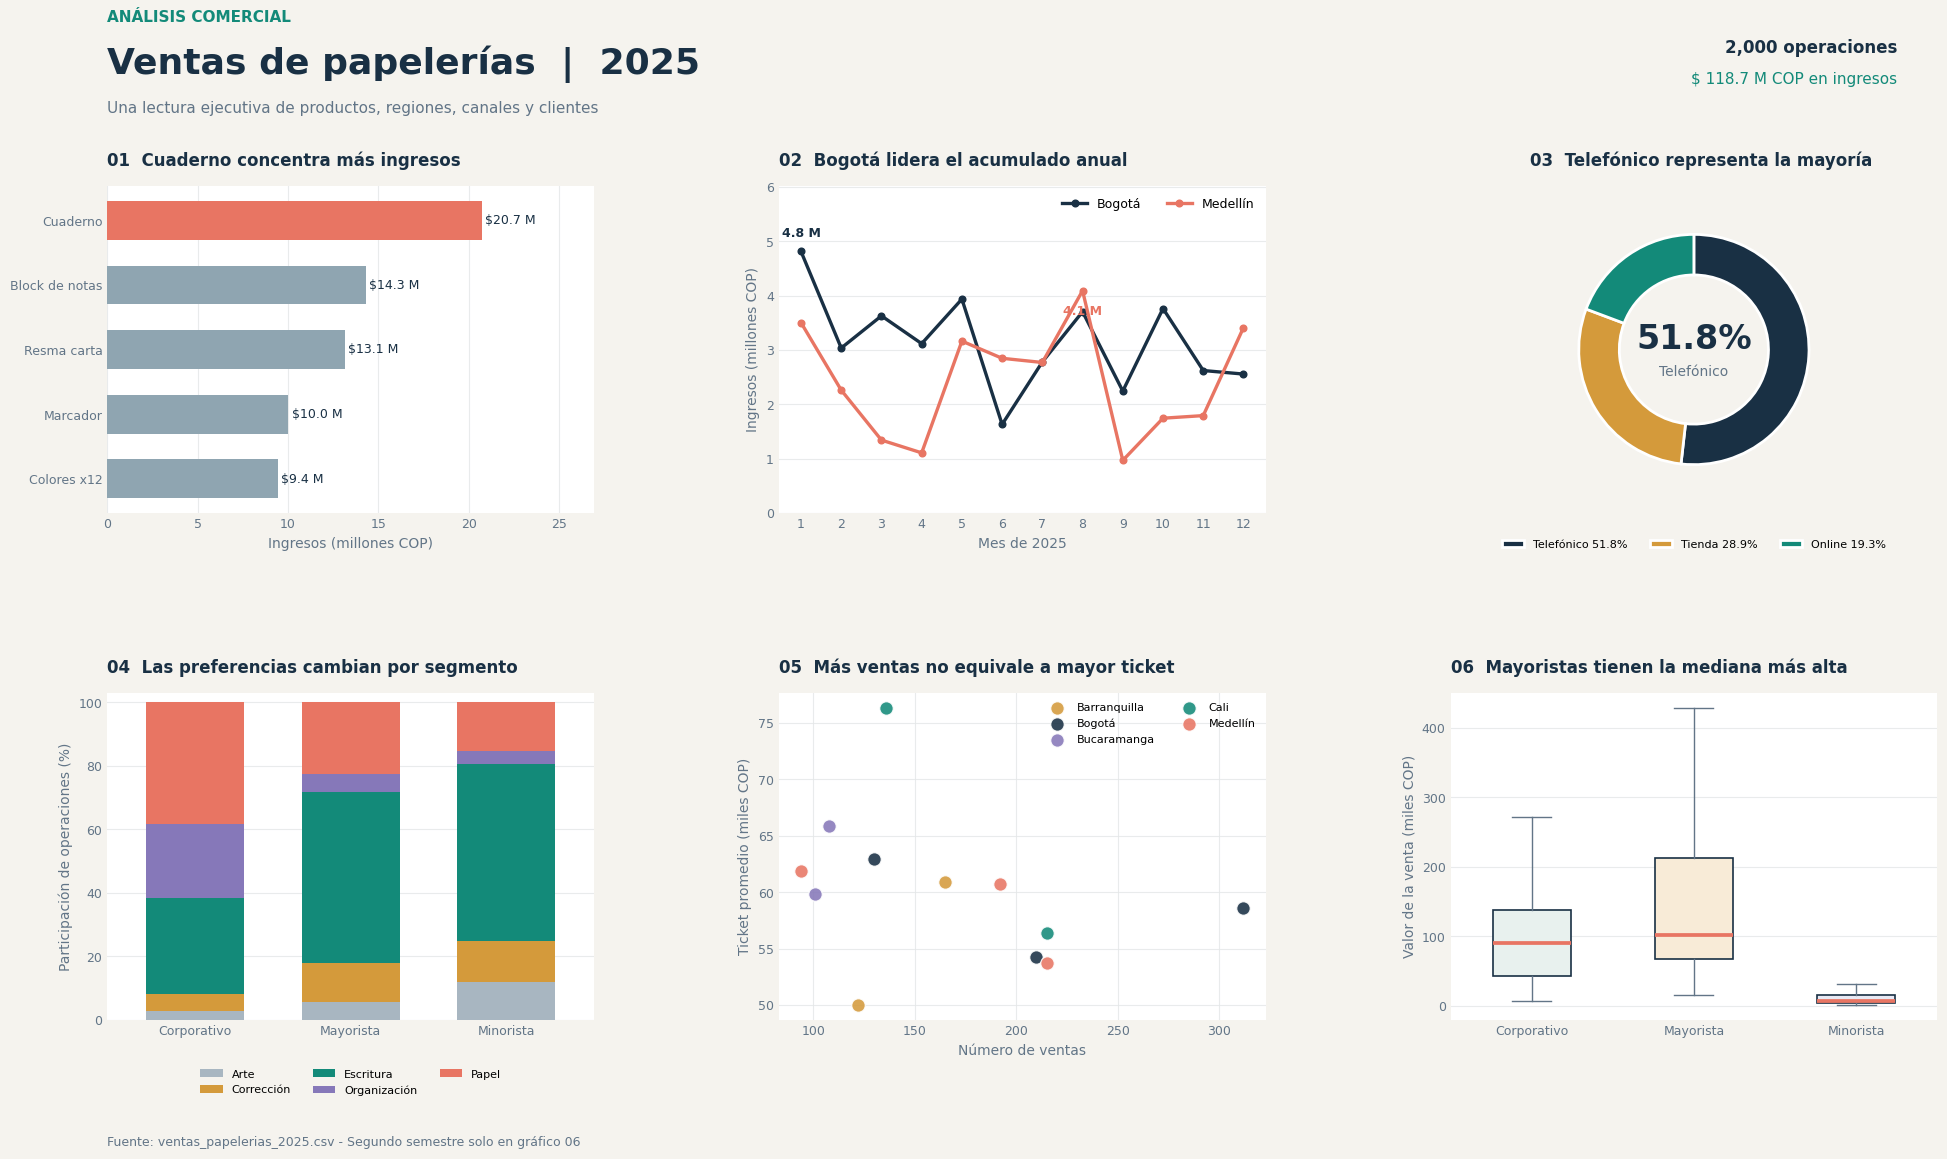

Hallazgos:
• Bogotá fue la ciudad con mayores ingresos en 2025, con $37.847.614, equivalentes al 31,9 % del total.
• El canal Telefónico generó $61.450.716, representando el 51,8 % de los ingresos totales de la cadena.
• Cuaderno fue el producto con mayores ingresos, alcanzando $20.712.345, equivalentes al 17,5 % del total.


In [62]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.

In [62]:
### Correcciones realizadas con inteligencia artificial

1. En la primera versión, el dashboard se veía muy básico y los resultados importantes no resaltaban lo suficiente. Por eso, le pedimos a la IA que utilizara colores más llamativos, mejorara los títulos y destacara los datos principales.

2. En la segunda versión, queríamos que los gráficos fueran más fáciles de interpretar. Por eso, solicitamos convertir el gráfico circular en una dona, resaltar el producto Cuaderno y señalar los meses con mayores ingresos, sin modificar las cifras originales.

3. Finalmente, consideramos que el dashboard podía tener una presentación más profesional. Por eso, pedimos una tercera versión con tarjetas de indicadores, una mejor distribución visual y conclusiones destacadas, conservando los seis gráficos originales.